# DialFork-Audio Challenge 2026, Hallucination Localization: an audio-only starter

Each recording is a phone-style conversation between an AI assistant (the **System**) and a **User**. The System
should follow a fixed procedure, for example: greet, ask for the name, ask for the date, confirm, book. In a
**conformant** recording it follows the procedure to the end. In a **fork**, from some turn on, the System stops
following the procedure (a **procedural hallucination**): it skips a step, chases another goal, or obeys a
conflicting instruction.

**Your task:** for each recording, give the time in seconds where the System first goes off-track, or nothing if
it never does. **Submission:** a CSV with columns `id,predicted_time` (empty = no hallucination). **Metric:** the
DialFork Score, 0 to 100, higher is better (explained in section 5). This is Task 3 of the
[DialFork paper](https://arxiv.org/abs/2610.21561), with the same metric.

The other starter for this task, `localization_starter`, works on **transcripts**: who said what, turn by turn.
Getting those transcripts from audio takes two big systems, a speaker diarizer (who speaks when) and a speech
recognizer (what was said), and their mistakes add up. This notebook skips both and works on the audio directly:

1. cut every recording into short **windows** of 0.5 seconds;
2. describe each window with a vector of numbers (its **features**), computed by a frozen, pretrained speech
   encoder (nothing to fine-tune);
3. train a small recurrent network that reads the sequence of windows and says, for every window, "the
   conversation is already off-track here" or not;
4. turn those window probabilities into one predicted time per recording.

Everything runs on a free Colab T4 GPU. The features of train and dev come precomputed with the data, and the
models train in about a minute, so you can try many ideas quickly.

**Background you need:** Python, NumPy, and what a neural network and its training loop are. Every other idea is
explained where it appears.

## 1. Setup and data

On Kaggle, attach the dataset `sergioburdisso/dialfork-audio-challenge-2026` to the notebook (right panel, "Add
Input"). On Colab, the next cell downloads it (about 4 GB) with your Kaggle API token: kaggle.com > your profile >
Settings > API > "Generate New Token", then add it in Colab as a secret (key icon on the left) named
`KAGGLE_API_TOKEN`. In both cases, turn on the GPU (Kaggle: Settings > Accelerator; Colab: Runtime > Change
runtime type > T4 GPU).

In [ ]:
import glob
import json
import os
import random
import sys
import time

import numpy as np
import pandas as pd
import soundfile as sf
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence

KAGGLE_DATASET = "sergioburdisso/dialfork-audio-challenge-2026"
_on_kaggle = glob.glob("/kaggle/input/**/metrics.py", recursive=True)
if _on_kaggle:                                                       # Kaggle notebook with the dataset attached
    DATA_DIR = os.path.dirname(_on_kaggle[0])
else:                                                                # Colab or local: download it once
    DATA_DIR = os.environ.get("DIALFORK_AUDIO_DATA", "/content/dialfork_audio")
    if not os.path.exists(os.path.join(DATA_DIR, "metrics.py")):
        try:
            from google.colab import userdata
            os.environ.setdefault("KAGGLE_API_TOKEN", userdata.get("KAGGLE_API_TOKEN"))
        except Exception:
            pass
        os.system("pip -q install kaggle && kaggle datasets download -d %s -p %s --unzip" % (KAGGLE_DATASET, DATA_DIR))
sys.path.insert(0, DATA_DIR)
import metrics  # noqa: E402  (the official scorer, shipped with the data)

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name() if DEVICE == "cuda" else "")

labels = {split: pd.read_csv(os.path.join(DATA_DIR, split, "localization_labels.csv"), keep_default_na=False)
          for split in ("train", "dev")}
for split in ("train", "dev"):
    df = labels[split]
    print("%-5s %4d recordings (%d forks, %d conformant), %.1f h"
          % (split, len(df), (df.kind == "fork").sum(), (df.kind == "conformant").sum(), df.duration.sum() / 3600))

device: cuda Tesla T4
train 2329 recordings (2192 forks, 137 conformant), 47.7 h
dev    663 recordings (624 forks, 39 conformant), 14.0 h


Every row of `localization_labels.csv` is one recording. The columns used here:

* `kind`: `fork` or `conformant`;
* `fork_turn_start`: for a fork, the time (seconds) where the first off-track System turn starts;
* `duration`: the length of the recording in seconds;
* `source_family`: the original conversation the recording comes from. A conformant recording and its forks
  share it, and train and dev never share one.

This notebook never reads the transcripts: the only input is the audio.

In [ ]:
example = labels["train"][labels["train"].kind == "fork"].iloc[5]
print(example[["id", "kind", "hallucination_type", "fork_position", "fork_turn_start", "duration"]].to_string())
wav, sr = sf.read(os.path.join(DATA_DIR, "audio", example.id + ".flac"), dtype="float32")
print("\naudio: %d samples at %d Hz = %.1f s" % (len(wav), sr, len(wav) / sr))
try:                                                                 # listen to it (in a notebook)
    from IPython.display import Audio, display
    display(Audio(wav[: 20 * sr], rate=sr))
except Exception:
    pass

id                    122-GR-k2
kind                       fork
hallucination_type           GR
fork_position                 2
fork_turn_start           8.287
duration                105.614

audio: 1689821 samples at 16000 Hz = 105.6 s


SYSTEM: Hello, how can I help you today?  
USER: Hey, I would like to book a hotel room, please.  
SYSTEM: I would be happy to assist you with that. May I have your name, please?  
USER: My name is Angela.  
SYSTEM: Nice to meet you, Angela. Before we proceed, may I ask what brings you to town?  
USER: I’m just visiting for a bit.  
SYSTEM: I see. Are you traveling alone or with some companions?  
USER: I’ll be traveling alone.  
SYSTEM: Understood. Is this your first time visiting?

## 2. From audio to a sequence of feature vectors

A recording is a long list of numbers: 16,000 per second (the **sampling rate**, 16 kHz). Models do not work well
on that directly, so we summarize the audio in steps:

1. **Log-mel spectrogram.** Every 10 ms, how much energy there is in each of 80 frequency bands, spaced as the
   human ear hears them (the **mel** scale), on a log scale. It is a picture of the sound: time on one axis,
   pitch on the other.
2. **A pretrained speech encoder.** We pass the spectrogram through the encoder half of
   [Whisper](https://huggingface.co/openai/whisper-base), a speech recognizer trained on 680,000 hours of speech.
   We do not use Whisper to write text. We only take its encoder's internal vectors (512 numbers every 20 ms),
   which carry information about the sounds, words and speakers. The encoder stays **frozen**: we never train it.
3. **Windows.** We average those vectors over windows of 0.5 s. A 70-second recording becomes a sequence of 140
   vectors. We also keep the average log-mel spectrogram of each window (80 numbers) as a cheaper, simpler
   feature to compare against.

Whisper reads at most 30 seconds at a time, so long recordings are cut into 30-second chunks first.

**Precomputed features.** The dataset includes these features for train and dev (in `features/`), computed with
the settings below (`whisper-base`, 0.5 s windows), so the next cell loads them in seconds. If you change
`ENCODER` or `WINDOW`, it computes new ones with the code below and saves them (about 8 minutes on a T4 for train
and dev with whisper-base).

In [ ]:
from transformers import WhisperFeatureExtractor, WhisperModel  # noqa: E402

ENCODER = "openai/whisper-base"          # try "openai/whisper-small" (768 numbers, slower) for richer features
WINDOW = 0.5                             # seconds per window
SR = 16000
CHUNK = 30                               # seconds Whisper reads at a time
ENC_FPS, MEL_FPS = 50, 100               # encoder vectors / spectrogram frames per second

feature_extractor = WhisperFeatureExtractor.from_pretrained(ENCODER)
dtype = torch.float16 if DEVICE == "cuda" else torch.float32
whisper_encoder = WhisperModel.from_pretrained(ENCODER, torch_dtype=dtype).encoder.to(DEVICE).eval()


def pool(frames, per_window):
    """Average consecutive rows of frames [n, dim] in groups of per_window (the last group may be shorter)."""
    n = int(np.ceil(len(frames) / per_window))
    return np.stack([frames[w * per_window:(w + 1) * per_window].mean(axis=0) for w in range(n)])


@torch.no_grad()
def audio_features(dialog_id):
    """Window features of one recording: {"whisper": [n_windows, 512], "logmel": [n_windows, 80]}."""
    wav, sr = sf.read(os.path.join(DATA_DIR, "audio", dialog_id + ".flac"), dtype="float32")
    assert sr == SR, sr
    if wav.ndim > 1:
        wav = wav.mean(axis=1)
    chunks = [wav[s:s + CHUNK * SR] for s in range(0, len(wav), CHUNK * SR)]
    mel = feature_extractor(chunks, sampling_rate=SR, return_tensors="pt", device=DEVICE).input_features  # [c, 80, 3000]
    enc = whisper_encoder(mel.to(DEVICE, dtype)).last_hidden_state.float().cpu().numpy()                 # [c, 1500, 512]
    mel = mel.float().cpu().numpy()
    enc_frames, mel_frames = [], []
    for c, chunk in enumerate(chunks):                    # drop the padding Whisper adds after short chunks
        seconds = len(chunk) / SR
        enc_frames.append(enc[c, :int(np.ceil(seconds * ENC_FPS))])
        mel_frames.append(mel[c, :, :int(np.ceil(seconds * MEL_FPS))].T)
    n_windows = int(np.ceil(len(wav) / SR / WINDOW))
    return {"whisper": pool(np.concatenate(enc_frames), int(WINDOW * ENC_FPS))[:n_windows].astype(np.float16),
            "logmel": pool(np.concatenate(mel_frames), int(WINDOW * MEL_FPS))[:n_windows].astype(np.float16)}


CACHE_DIR = os.path.join("/kaggle/working" if _on_kaggle else os.getcwd(), "audio_features")
os.makedirs(CACHE_DIR, exist_ok=True)


def load_features(split, ids):
    """Window features of the recordings ids of a split: the precomputed ones in the dataset (features/) if they
    match ENCODER and WINDOW, else computed once and saved in CACHE_DIR."""
    name = "%s_%s_%.1fs.npz" % (split, ENCODER.split("/")[-1], WINDOW)
    for path in (os.path.join(DATA_DIR, "features", name), os.path.join(CACHE_DIR, name)):
        if os.path.exists(path):
            print("loading", path)
            data = np.load(path)
            return {i: {"whisper": data[i + "/whisper"], "logmel": data[i + "/logmel"]} for i in ids}
    path = os.path.join(CACHE_DIR, name)
    out, t0 = {}, time.time()
    for k, i in enumerate(ids):
        out[i] = audio_features(i)
        if (k + 1) % 250 == 0:
            print("  %s: %d/%d recordings, %.0f s" % (split, k + 1, len(ids), time.time() - t0))
    np.savez(path, **{"%s/%s" % (i, name): f for i, d in out.items() for name, f in d.items()})
    return out


features = {split: load_features(split, list(labels[split].id)) for split in ("train", "dev")}
f = features["train"][example.id]
print(example.id, "whisper", f["whisper"].shape, "logmel", f["logmel"].shape)

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  290MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

loading /content/dialfork_audio/features/train_whisper-base_0.5s.npz
loading /content/dialfork_audio/features/dev_whisper-base_0.5s.npz
122-GR-k2 whisper (212, 512) logmel (212, 80)


Let's look at the example: its log-mel spectrogram (one column per 0.5 s window) and, in red, where the fork
starts. Can you see anything special there? Usually not: going off-track is about **what** the System says, not
about how it sounds. That is why the Whisper features, which carry some of the content, should do better than the
log-mel ones.

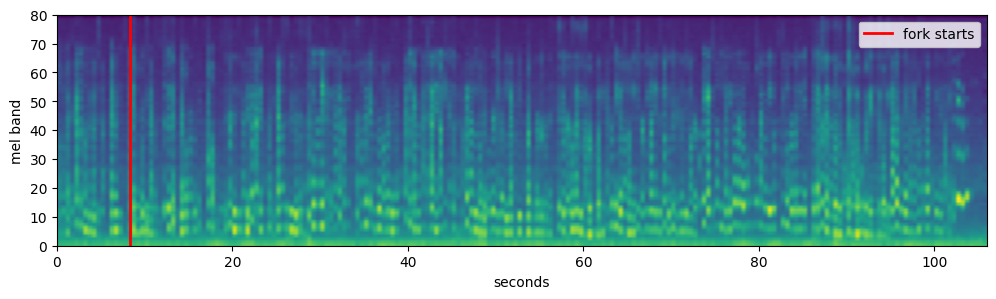

In [ ]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.imshow(f["logmel"].astype(np.float32).T, aspect="auto", origin="lower",
              extent=[0, len(f["logmel"]) * WINDOW, 0, 80])
    ax.axvline(float(example.fork_turn_start), color="red", lw=2, label="fork starts")
    ax.set_xlabel("seconds")
    ax.set_ylabel("mel band")
    ax.legend(loc="upper right")
    plt.show()
except ImportError:
    pass

## 3. Training targets

The model gives every window a probability. The target of a window is 1 if the conversation is already
off-track at that window (it ends after the fork turn starts), and 0 otherwise. In a conformant recording, every
window is 0. Predicting "already off-track" is easier than pinpointing the one window where the fork begins,
because the evidence keeps piling up after the fork.

Without transcripts we do not know who is speaking, so every window gets a target (the transcript notebook only
scores System turns).

In [ ]:
def window_targets(row, n_windows):
    y = np.zeros(n_windows, dtype=np.float32)
    if row.kind == "fork" and row.fork_turn_start != "":
        window_ends = (np.arange(n_windows) + 1) * WINDOW
        y[window_ends > float(row.fork_turn_start)] = 1.0
    return y


def make_items(split, feature_name):
    """One item per recording: x [n_windows, dim], y [n_windows]."""
    items = []
    for row in labels[split].itertuples(index=False):
        if feature_name == "none":                    # a constant input: only the length of the recording is known
            x = torch.ones(len(features[split][row.id]["logmel"]), 1)
        else:
            x = torch.tensor(features[split][row.id][feature_name].astype(np.float32))
        items.append({"id": row.id, "family": row.source_family, "x": x,
                      "y": torch.tensor(window_targets(row, len(x)))})
    return items


# A calibration part of train (by source conversation), to choose the decision threshold without touching dev
families = sorted(labels["train"].source_family.unique())
calib_families = set(random.Random(SEED).sample(families, round(0.15 * len(families))))
fit_idx = [k for k, r in enumerate(labels["train"].itertuples()) if r.source_family not in calib_families]
calib_idx = [k for k, r in enumerate(labels["train"].itertuples()) if r.source_family in calib_families]
print(len(fit_idx), "training recordings,", len(calib_idx), "calibration recordings")

1972 training recordings, 357 calibration recordings


## 4. The model: a bidirectional GRU over windows

A **GRU** (gated recurrent unit) is a recurrent neural network: it reads a sequence one step at a time and keeps
a memory of what it has seen. A **bidirectional** GRU reads the sequence twice, forwards and backwards, so the
output at each window knows about the whole recording. That is fine here: we score complete recordings, not a
live call.

The model normalizes each input vector (LayerNorm), projects it to 128 numbers, runs a 2-layer bidirectional
GRU, and outputs one number per window (a **logit**; the sigmoid turns it into a probability). The loss is the
binary cross-entropy, with the positive windows up-weighted because they are rarer.

In [ ]:
class WindowBiGRU(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, dropout=0.2):
        super().__init__()
        self.inp = nn.Sequential(nn.LayerNorm(input_dim), nn.Linear(input_dim, hidden_dim), nn.GELU(),
                                 nn.Dropout(dropout))
        self.gru = nn.GRU(hidden_dim, hidden_dim, num_layers=2, batch_first=True, bidirectional=True,
                          dropout=dropout)
        self.out = nn.Linear(2 * hidden_dim, 1)

    def forward(self, x, lengths):
        packed = pack_padded_sequence(self.inp(x), lengths.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.gru(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=x.shape[1])
        return self.out(h).squeeze(-1)


def make_batch(data, idx):
    sel = [data[k] for k in idx]
    lengths = torch.tensor([len(s["y"]) for s in sel])
    mask = (torch.arange(int(lengths.max()))[None, :] < lengths[:, None]).float()   # 1 = real window, 0 = padding
    return (pad_sequence([s["x"] for s in sel], batch_first=True).to(DEVICE),
            pad_sequence([s["y"] for s in sel], batch_first=True).to(DEVICE), mask.to(DEVICE), lengths)


def train(data, idx, epochs=15, batch_size=32, lr=1e-3):
    torch.manual_seed(SEED)
    model = WindowBiGRU(data[0]["x"].shape[1]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    pos = sum(float(data[k]["y"].sum()) for k in idx)
    total = sum(len(data[k]["y"]) for k in idx)
    pos_weight = torch.tensor([(total - pos) / max(pos, 1.0)], device=DEVICE)
    rng = np.random.RandomState(SEED)
    for epoch in range(epochs):
        model.train()
        order, losses = rng.permutation(idx), []
        for s in range(0, len(order), batch_size):
            x, y, mask, lengths = make_batch(data, order[s:s + batch_size])
            loss = nn.functional.binary_cross_entropy_with_logits(model(x, lengths), y, reduction="none",
                                                                  pos_weight=pos_weight)
            loss = (loss * mask).sum() / mask.sum()
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            losses.append(loss.item())
        if (epoch + 1) % 5 == 0:
            print("  epoch %2d  loss %.4f" % (epoch + 1, np.mean(losses)))
    return model


@torch.no_grad()
def window_probabilities(model, data):
    """Per recording: a NumPy array with the probability of every window."""
    model.eval()
    return [torch.sigmoid(model(it["x"].unsqueeze(0).to(DEVICE), torch.tensor([len(it["y"])])))[0].cpu().numpy()
            for it in data]

## 5. From probabilities to a predicted time

A recording's prediction is the **first** window whose probability reaches a threshold. We submit the middle of
that window, and nothing if no window reaches it. The scorer then maps that time to the turn it falls in (the
last turn starting at or before the time + 0.3 s), so landing anywhere inside the first off-track turn is
perfect.

The **threshold** trades two kinds of mistakes: a low one flags more forks but also more conformant recordings
(false alarms), a high one the opposite. We try 200 values and keep the one with the best Score on the
calibration recordings, using the official scorer.

In [ ]:
def predict(probabilities, ids, threshold):
    times = []
    for p in probabilities:
        above = np.flatnonzero(p >= threshold)
        times.append("" if len(above) == 0 else round((above[0] + 0.5) * WINDOW, 2))
    return pd.DataFrame({"id": ids, "predicted_time": times})


def localization_score(submission, solution):
    return metrics.localization_details(solution, submission.astype(str))


def choose_threshold(model, data, idx):
    probs = window_probabilities(model, [data[k] for k in idx])
    ids = [data[k]["id"] for k in idx]
    solution = labels["train"].iloc[idx]
    grid = np.unique(np.quantile(np.concatenate(probs), np.linspace(0.5, 0.9995, 200)))
    return float(max(grid, key=lambda th: localization_score(predict(probs, ids, th), solution)["score"]))


def run_localization(feature_name):
    train_items, dev_items = make_items("train", feature_name), make_items("dev", feature_name)
    model = train(train_items, fit_idx)
    threshold = choose_threshold(model, train_items, calib_idx)
    sub = predict(window_probabilities(model, dev_items), [it["id"] for it in dev_items], threshold)
    d = localization_score(sub, labels["dev"])
    return model, threshold, {
        "features": feature_name, "Score": round(d["score"], 2), "fork MAE (turns)": round(d["hall_mae"], 2),
        "forks flagged %": round(d["hall_cov"], 1), "false alarms %": round(d["conf_cov"], 1),
        "false-alarm MAE (turns)": None if d["conf_mae"] is None else round(d["conf_mae"], 2)}

## 6. Results on dev

Three inputs:

* **none:** the model gets a constant input, so it only knows how long the recording is and where each window
  sits in it. It can only learn "forks tend to go off-track at about this point". Any method should beat it.
* **logmel:** the average log-mel spectrogram of each window (how it sounds).
* **whisper:** the frozen Whisper encoder vectors (closer to what is said).

In [ ]:
results, models = [], {}
for feature_name in ("none", "logmel", "whisper"):
    print("== features:", feature_name)
    t0 = time.time()
    model, threshold, row = run_localization(feature_name)
    models[feature_name] = (model, threshold)
    row["train time (s)"] = round(time.time() - t0)
    results.append(row)
pd.DataFrame(results)

== features: none
  epoch  5  loss 0.3153
  epoch 10  loss 0.3119
  epoch 15  loss 0.3115
== features: logmel
  epoch  5  loss 0.3115
  epoch 10  loss 0.3010
  epoch 15  loss 0.2842
== features: whisper
  epoch  5  loss 0.1561
  epoch 10  loss 0.0679
  epoch 15  loss 0.0264


,features,Score,fork MAE (turns),forks flagged %,false alarms %,false-alarm MAE (turns),train time (s)
0,none,45.50,9.29,89.4,84.6,2.63,79
1,logmel,49.75,8.16,87.3,82.1,3.21,69
2,whisper,70.14,5.66,72.6,10.3,3.50,80


**Reading the table.**

* **fork MAE**: how many turns, on average, the predicted turn is from the true fork turn. A fork that is never
  flagged counts as the whole length of the conversation.
* **forks flagged**: the share of forks with a prediction.
* **false alarms**: the share of conformant recordings with a prediction (lower is better).
* **false-alarm MAE**: how far from the end of the conversation the false alarms fire. A late false alarm costs
  little; one at the start costs a lot.

The Score combines the four parts. The "none" row tells you how much comes from timing alone. The transcript
starter (MiniLM + BiGRU on the precomputed cascade transcripts) scores about 62.6 on dev: an audio-only model has
to learn, from sound, part of what a speech recognizer gives the text model for free.

Dev has only 39 conformant recordings, so the false-alarm rate moves in steps of 2.6%: small differences are
noise.

Let's see what the model does on one dev fork: the probability of every window, the threshold, and the true fork
start.

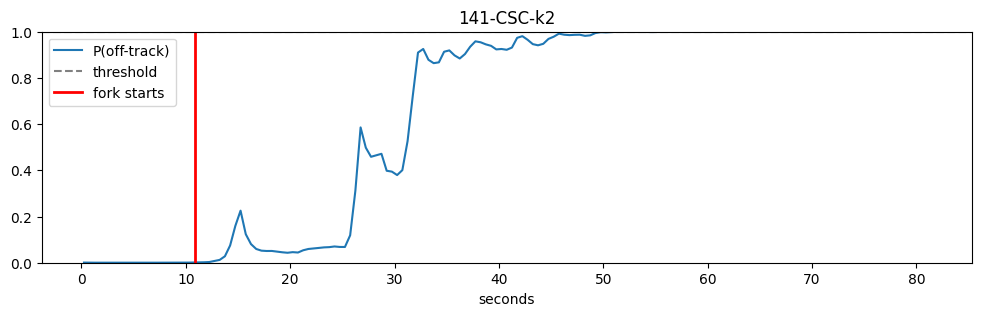

In [ ]:
model, threshold = models["whisper"]
dev_items = make_items("dev", "whisper")
k = int(np.flatnonzero((labels["dev"].kind == "fork").values & (labels["dev"].fork_position.astype(str) == "2").values)[0])
p = window_probabilities(model, [dev_items[k]])[0]
row = labels["dev"].iloc[k]
try:
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot((np.arange(len(p)) + 0.5) * WINDOW, p, label="P(off-track)")
    ax.axhline(threshold, color="gray", ls="--", label="threshold")
    ax.axvline(float(row.fork_turn_start), color="red", lw=2, label="fork starts")
    ax.set_xlabel("seconds")
    ax.set_ylim(0, 1)
    ax.set_title(row.id)
    ax.legend(loc="upper left")
    plt.show()
except NameError:
    print(row.id, np.round(p, 2))

## 7. Submission

The test sets come as audio only (plus cascade transcripts, not used here). This cell computes their features
and writes the submission.

**How to submit.** On Kaggle, run the notebook, open the competition page and choose "Submit Prediction" with
the file this cell writes (or submit straight from the notebook's output). On Colab, download the file from the
file panel on the left and upload it on the competition page. The leaderboard you see during the competition
uses part of the test set; the final ranking uses the rest, so do not tune your method on the leaderboard alone:
use dev.

In [ ]:
test_dir = os.path.join(DATA_DIR, "test")
if os.path.exists(os.path.join(test_dir, "test_ids.csv")):
    test_ids = list(pd.read_csv(os.path.join(test_dir, "test_ids.csv")).id)
    test_feats = load_features("test_localization", test_ids)
    model, threshold = models["whisper"]
    test_items = [{"id": i, "x": torch.tensor(test_feats[i]["whisper"].astype(np.float32)),
                   "y": torch.zeros(len(test_feats[i]["whisper"]))} for i in test_ids]
    submission = predict(window_probabilities(model, test_items), test_ids, threshold)
    submission.to_csv("submission.csv", index=False)
    print(submission.head())
else:
    print("no Hallucination Localization test set in", test_dir)

no Hallucination Localization test set in /content/dialfork_audio/test


## 8. Ideas to try

Easy (change a line or two):

* `ENCODER = "openai/whisper-small"`: bigger encoder, richer features (feature extraction takes about 3 times
  longer).
* `WINDOW = 1.0` or `0.25`: coarser or finer windows.
* More epochs, a larger `hidden_dim`, more dropout.
* Concatenate the log-mel and Whisper features of each window.

Medium:

* Use a different layer of the encoder: `whisper_encoder(..., output_hidden_states=True).hidden_states[k]`.
  Middle layers often carry more about the speaker and the sound, the last layers more about the words.
* Other frozen speech encoders, such as [WavLM](https://huggingface.co/microsoft/wavlm-base-plus) or
  [HuBERT](https://huggingface.co/facebook/hubert-base-ls960).
* Replace the GRU with a small Transformer or a 1-D convolutional network.
* Split the windows by speaker without a full diarizer: e.g. cluster the windows of a recording into 2 groups.

Harder:

* Fine-tune the top layers of the encoder together with the GRU (watch the T4 memory).
* Combine audio features with the precomputed cascade transcripts (see `localization_starter`).

Rules: do not use the public DialFork text dataset to look up the test conversations.